# Heat-Risk Screening — Deliverable 3 (Final Integrated Notebook)

**Course:** Computational Data Analysis with Python (CDAP), TUM
**Track 1 — Heat-risk screening** · Kriti Shrestha & Jonas Juchelka

This notebook is the final, standalone synthesis of the project. It runs top to
bottom from a clean kernel and does not depend on the Deliverable 1 or 2
notebooks. It carries its own data-loading code and reads the shared dataset
from `../archive/`.

We study urban summer heat exposure across six European cities and build a
screening tool that flags the hottest measurement locations. The notebook walks
the full path from the question, through the data and its quality, the analysis
and its validation, to an honest read of uncertainty and a concrete
recommendation a city could act on.

## 0. Setup

We import the scientific Python stack and scikit-learn, fix a single random
seed so every result is reproducible, and set a consistent plotting style.
Nothing here is analysis yet; it just prepares the environment.

In [1]:
from pathlib import Path
import re
import unicodedata
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import (
    StratifiedKFold, GroupKFold, cross_val_predict, cross_val_score,
    GridSearchCV, learning_curve,
)
from sklearn.metrics import (
    roc_auc_score, average_precision_score, roc_curve, precision_recall_curve,
    precision_score, recall_score, f1_score, matthews_corrcoef,
    confusion_matrix, ConfusionMatrixDisplay,
)

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (10, 5)
warnings.filterwarnings('ignore', category=FutureWarning)

print('Libraries loaded.')
print(f'pandas {pd.__version__}, numpy {np.__version__}, sklearn loaded')

Libraries loaded.
pandas 2.3.3, numpy 2.4.4, sklearn loaded


## 1. Question and motivation

Cities are getting hotter, and the heat is not spread evenly. Within a single
city some streets and squares run several degrees warmer than others. Those hot
spots carry real health risks. Prolonged heat causes heat stress and heat
stroke, and it raises summer deaths, above all among the elderly, young
children, and people with heart or lung conditions. A person's exposure depends
heavily on where they live and spend the day. Knowing which locations run
hottest is therefore useful public-health information.

This project builds a screening tool for that question. A city has a limited
budget for cooling measures such as shade, trees, and water features. It cannot
treat every location, so it needs a way to rank locations by heat and decide
where to look first. That is a screening problem. We want a method that flags
the hottest measurement stations so a planner can shortlist them for closer
study.

We measure a station's heat with the 95th percentile of its hourly summer air
temperature, written p95. This captures how hot a station gets during its
hottest hours without over-reacting to a single freak reading. We then study
heat risk through two lenses. The absolute lens ranks stations across all
cities, so it is mostly about which city is warmest. The within-city lens ranks
stations inside their own city, so it isolates microclimate, the local
differences that planning can actually change. A planner needs both. The
absolute view says which cities run hottest. The within-city view says where
the local hot spots sit inside a given city.

The data covers 375 stations across six European cities (Zurich, Basel, Bern,
Birmingham, Amsterdam, and Berlin). Our success criterion is an honest and
useful screen, not a high accuracy score. We would rather report a modest result
we can trust, with its uncertainty stated plainly, than a flattering number we
cannot defend.

## 2. The data

The dataset is **FAIRUrbTemp**, a curated collection of urban air-temperature
measurements from European cities. Each city has a set of fixed measurement
stations, and each station records hourly **air temperature** (`ta`) in degrees
Celsius. Air temperature is the only measured variable; everything else we use
is station context (where the station is, how high its sensor sits).

The files are stored in **SEF (Station Exchange Format)**: a 12-line header
with station identity and units, then a tab-separated table whose key column is
`Value` (the temperature) alongside `Year, Month, Day, Hour, Minute`. Missing
readings appear either as the literal text `NA` or as the sentinel `-999`; we
fold both into proper missing values so they never pollute a temperature
average. Our **unit of analysis is the station**: every row of the modeling
table we build later is one station.

### 2.1 Load the hourly records

We parse every station file into one long table. Two details matter for
correctness. First, a station's id is the filename stem before `_AirTemp_`,
which keeps compound ids such as `AWEL_Blumenfeld` intact. Second, we normalise
ids to Unicode NFC so that stations with umlauts (for example Basel's
`Münsterplatz`) match the metadata files later; macOS stores the filenames in a
different normalisation (NFD) than the metadata tables (NFC), and without this
step those stations would silently fail to merge.

In [2]:
ARCHIVE = Path('../archive')
HOURLY_DIR = ARCHIVE / 'data' / 'hourly'
META_DIR   = ARCHIVE / 'data' / 'metadata'
CACHE_DIR  = Path('cache'); CACHE_DIR.mkdir(exist_ok=True)
HOURLY_PARQUET = CACHE_DIR / 'hourly_long.parquet'

assert HOURLY_DIR.exists(), f'Dataset not found at {HOURLY_DIR.resolve()}'

def parse_sef_file(path: Path) -> pd.DataFrame:
    """Parse one FAIRUrbTemp SEF TSV into long format (city, station_id, datetime, ta).

    station_id is the filename stem before '_AirTemp_' (handles 'D2195' and
    'AWEL_Blumenfeld'), Unicode-normalized to NFC so umlaut station names match
    the metadata TSVs. '-999' is a missing-value sentinel folded into NA.
    """
    df = pd.read_csv(
        path, sep='\t', skiprows=12, na_values=['NA', '-999', '-999.0'],
        dtype={'Year':'Int64','Month':'Int64','Day':'Int64','Hour':'Int64','Minute':'Int64'},
        low_memory=False,
    )
    parts = df[['Year','Month','Day','Hour','Minute']].rename(columns=str.lower)
    return pd.DataFrame({
        'city': path.parent.name,
        'station_id': unicodedata.normalize('NFC', path.stem.split('_AirTemp_')[0]),
        'datetime': pd.to_datetime(parts),
        'ta': pd.to_numeric(df['Value'], errors='coerce'),
    })

if HOURLY_PARQUET.exists():
    print(f'Loading cached parquet {HOURLY_PARQUET} ...')
    hourly = pd.read_parquet(HOURLY_PARQUET)
else:
    print('Parsing SEF files (first run, ~1-2 min) ...')
    files = [f for c in sorted(HOURLY_DIR.iterdir()) if c.is_dir()
             for f in sorted(c.glob('*.tsv'))]
    hourly = pd.concat([parse_sef_file(f) for f in files], ignore_index=True)
    hourly['city'] = hourly['city'].astype('category')
    hourly['station_id'] = hourly['station_id'].astype('category')
    hourly.to_parquet(HOURLY_PARQUET, index=False)
    print(f'Saved {HOURLY_PARQUET} ({HOURLY_PARQUET.stat().st_size/1e6:.1f} MB)')

print(f'Loaded {len(hourly):,} rows, {hourly.station_id.nunique()} stations, '
      f'{hourly.city.nunique()} cities')

Loading cached parquet cache/hourly_long.parquet ...


Loaded 16,969,491 rows, 712 stations, 9 cities


## 3. From raw records to a modeling table

We now turn millions of hourly readings into one row per station with a heat
measure and the features we will model. Every transformation here is
reproducible and explained, because the quality of this step decides whether
the later model means anything.

### 3.1 Heat measure and the two definitions of "hotspot"

For each station we summarise its summers (June to August, 2019-2022) with the
**95th percentile of hourly air temperature** (`p95`). The 95th percentile
captures how hot a station gets during its hottest hours, while ignoring a
single freak reading that a plain maximum would over-react to. We keep only
stations with at least 50% of the possible summer hours, so a sparse station
cannot produce a noisy percentile.

We then label "hotspots" two different ways, and the contrast between them is
the analytical heart of this project:

- **Absolute hotspot** — the station's `p95` is in the top quartile across *all*
  stations in *all* cities. This is dominated by climate: a warm city's stations
  are hot in absolute terms.
- **Within-city (local) hotspot** — the station's `p95` is in the top quartile
  *inside its own city*. This removes the city's background climate and isolates
  **microclimate**: which spots run hot relative to their neighbours.

A planner needs both. The absolute view says which cities run hottest; the
within-city view says where the local hotspots sit inside a given city.

In [3]:
STUDY_YEARS = [2019, 2020, 2021, 2022]
SUMMER_MONTHS = [6, 7, 8]
MAX_OBS = len(STUDY_YEARS) * 92 * 24    # theoretical max summer hours
MIN_AVAILABILITY = 0.50

m = (hourly['datetime'].dt.year.isin(STUDY_YEARS)
     & hourly['datetime'].dt.month.isin(SUMMER_MONTHS))
summer = hourly.loc[m].dropna(subset=['ta']).copy()

n_obs = summer.groupby('station_id', observed=True).size()
keep = n_obs[n_obs >= MIN_AVAILABILITY * MAX_OBS].index
summer = summer[summer['station_id'].isin(keep)]

risk = (summer.groupby(['city', 'station_id'], observed=True)['ta']
        .quantile(0.95).reset_index(name='p95'))

risk['is_hotspot_absolute'] = (risk['p95'] >= risk['p95'].quantile(0.75)).astype(int)
risk['is_local_hotspot'] = (
    risk.groupby('city', observed=True)['p95']
        .transform(lambda s: (s >= s.quantile(0.75)).astype(int))
)

print(f'Stations after availability filter: {len(risk)} across {risk.city.nunique()} cities')
print(f'Absolute hotspot rate: {risk.is_hotspot_absolute.mean():.0%}')
print(f'Local hotspot rate:    {risk.is_local_hotspot.mean():.0%}')
print('\nAbsolute hotspots by city (expect Zurich-dominated):')
print(risk[risk.is_hotspot_absolute == 1].city.value_counts().to_string())
print('\nLocal hotspots by city (expect spread across cities):')
print(risk[risk.is_local_hotspot == 1].city.value_counts().to_string())

assert 350 <= len(risk) <= 400, f'unexpected station count {len(risk)}'
for col in ['is_hotspot_absolute', 'is_local_hotspot']:
    assert 0.20 <= risk[col].mean() <= 0.30, f'{col} rate off'

Stations after availability filter: 375 across 6 cities
Absolute hotspot rate: 25%
Local hotspot rate:    26%

Absolute hotspots by city (expect Zurich-dominated):
city
Zurich        72
Basel         11
Bern          11
Berlin         1
Amsterdam      0
Biel           0
Birmingham     0
Freiburg       0
NoviSad        0

Local hotspots by city (expect spread across cities):
city
Zurich        46
Basel         25
Bern          14
Birmingham     5
Amsterdam      3
Berlin         3
Biel           0
Freiburg       0
NoviSad        0


### 3.2 Station context features

A station's heat is driven by where it sits. We attach each station's
coordinates and sensor height from the metadata tables (normalising ids to NFC
again so umlaut stations match), then engineer features that describe a
station's position. All of these come only from geography and metadata, never
from the temperature record, so they cannot leak the answer into the model.

In [4]:
station_meta = pd.concat(
    [pd.read_csv(p, sep='\t') for p in sorted(META_DIR.glob('*/station_metadata_*.tsv'))],
    ignore_index=True,
)
station_meta['station_id'] = station_meta['station_id'].map(
    lambda s: unicodedata.normalize('NFC', str(s))
)

def parse_height(v):
    """'4 m' -> 4.0 ; '2-3 m' -> 2.5 ; 2.0 -> 2.0 ; junk -> NaN"""
    if pd.isna(v): return np.nan
    s = str(v).lower().replace('m', '').strip()
    if '-' in s:
        a, b = s.split('-', 1)
        try: return (float(a) + float(b)) / 2
        except ValueError: return np.nan
    try: return float(s)
    except ValueError: return np.nan

station_meta['sensor_height_parsed'] = station_meta['sensor_height_m'].apply(parse_height)

meta_cols = ['station_id', 'latitude', 'longitude', 'sensor_height_parsed']
if 'altitude_m' in station_meta.columns:
    meta_cols.append('altitude_m')
df = risk.merge(station_meta[meta_cols], on='station_id', how='left')
if 'altitude_m' not in df.columns:
    df['altitude_m'] = np.nan

def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0
    dlat = np.radians(lat2 - lat1); dlon = np.radians(lon2 - lon1)
    a = (np.sin(dlat/2)**2
         + np.cos(np.radians(lat1)) * np.cos(np.radians(lat2)) * np.sin(dlon/2)**2)
    return 2 * R * np.arcsin(np.sqrt(a))

cent = (df.groupby('city', observed=True)[['latitude', 'longitude']]
          .mean().rename(columns={'latitude': 'clat', 'longitude': 'clon'}))
df = df.merge(cent, on='city')
df['distance_to_centroid'] = haversine_km(df.latitude, df.longitude, df.clat, df.clon)
df['city'] = df['city'].astype(str)

assert df[['latitude', 'longitude']].notna().all().all(), \
    'some stations have no coordinates -> station_id mismatch with metadata'
print(f'All {len(df)} stations matched metadata coordinates.')

All 375 stations matched metadata coordinates.


**New spatial features (Deliverable 3).** Distance to the city centre is a coarse
position signal. We add three richer ones, all derived from the coordinates we
already hold:

- **Local station density** counts how many other stations lie within 1 km. A
  dense cluster of sensors usually marks a built-up core, a proxy for the kind of
  place that traps heat.
- **Neighbourhood heat (kNN p95)** is the average `p95` of the five nearest
  *other* stations. It asks whether a station sits in a hot pocket. Because this
  feature is built from temperatures, using it carelessly would leak the answer,
  so when we validate we recompute it inside each training fold (Section 6). The
  column built here is for exploration and the full-data view only.
- **Direction from the centre** (the compass bearing, split into its sine and
  cosine) lets the model learn that, say, the south side of a city runs hotter,
  which plain distance cannot express.

We also keep **elevation** where the metadata provides it; it is populated for
only a few cities, so it acts as a city-specific signal rather than a universal
one.

In [5]:
coords = df[['latitude', 'longitude']].to_numpy()
n = len(df)

# pairwise great-circle distances (n is small, ~375, so a dense matrix is fine)
dist_km = np.zeros((n, n))
for i in range(n):
    dist_km[i] = haversine_km(coords[i, 0], coords[i, 1], coords[:, 0], coords[:, 1])

# Local station density: other stations within 1 km (exclude self on the diagonal)
within_1km = (dist_km <= 1.0)
np.fill_diagonal(within_1km, False)
df['station_density_1km'] = within_1km.sum(axis=1)

# kNN-neighbour p95 (k=5 nearest OTHER stations), full-data version for EDA only
K = 5
p95_vals = df['p95'].to_numpy()
knn_p95 = np.empty(n)
for i in range(n):
    order = np.argsort(dist_km[i])
    order = order[order != i][:K]
    knn_p95[i] = p95_vals[order].mean()
df['knn_p95_k5'] = knn_p95

# Direction from the city centroid, as sine/cosine of the bearing
dlon = np.radians(df['longitude'] - df['clon'])
lat1 = np.radians(df['clat']); lat2 = np.radians(df['latitude'])
x = np.sin(dlon) * np.cos(lat2)
y = np.cos(lat1) * np.sin(lat2) - np.sin(lat1) * np.cos(lat2) * np.cos(dlon)
bearing = np.arctan2(x, y)
df['bearing_sin'] = np.sin(bearing)
df['bearing_cos'] = np.cos(bearing)

NUM_FEATURES_BASE = ['latitude', 'longitude', 'distance_to_centroid', 'sensor_height_parsed']
NUM_FEATURES_SPATIAL = ['station_density_1km', 'bearing_sin', 'bearing_cos', 'altitude_m']
NUM_FEATURES = NUM_FEATURES_BASE + NUM_FEATURES_SPATIAL
CAT_FEATURES = ['city']
FEATURES = NUM_FEATURES + CAT_FEATURES

print('New spatial features built. Summary:')
print(df[['station_density_1km', 'knn_p95_k5', 'bearing_sin', 'bearing_cos']].describe().round(2))
print('\naltitude_m non-missing by city:')
print(df.groupby('city')['altitude_m'].apply(lambda s: s.notna().sum()).to_string())
assert df['station_density_1km'].min() >= 0
assert df[['bearing_sin', 'bearing_cos']].abs().max().max() <= 1.0 + 1e-9

New spatial features built. Summary:
       station_density_1km  knn_p95_k5  bearing_sin  bearing_cos
count               375.00      375.00       375.00       375.00
mean                  5.59       29.44        -0.05         0.00
std                   4.02        1.47         0.68         0.73
min                   0.00       23.73        -1.00        -1.00
25%                   2.00       29.21        -0.73        -0.76
50%                   5.00       29.69        -0.04         0.04
75%                   8.00       30.14         0.62         0.75
max                  17.00       31.95         1.00         1.00

altitude_m non-missing by city:
city
Amsterdam       0
Basel           0
Berlin         10
Bern            0
Birmingham      0
Zurich        184


### 3.3 A leak-free preprocessing pipeline

Everything the model learns from the data must be learned on the training rows
only, never the rows we test on. We wrap preprocessing in a scikit-learn
`Pipeline` so that during cross-validation each step is fit on the training fold
and merely applied to the held-out fold. The numeric features are median-imputed
(the parsed sensor height and elevation have gaps) and standardised; the city is
left out of the model as a predictor because the within-city target already has
the city removed, and feeding the city back in would be circular. We keep `city`
only as a grouping key for the cross-city test in Section 6.

The neighbourhood-heat feature needs special care: its value for a station
depends on other stations' temperatures, so if a test station's neighbours
include training stations we must compute it using training neighbours only. We
implement it as a transformer that stores the training coordinates and p95 when
it is fit, and computes neighbour averages for any rows it later transforms.

In [6]:
from sklearn.base import BaseEstimator, TransformerMixin

class KNNNeighbourP95(BaseEstimator, TransformerMixin):
    """Append mean p95 of the k nearest TRAINING stations (leak-free).

    Expects input columns ['latitude','longitude','p95']; outputs one column.
    On fit it memorises training coords+p95; on transform it looks up neighbours
    among the training stations only."""
    def __init__(self, k=5):
        self.k = k
    def fit(self, X, y=None):
        A = np.asarray(X, dtype=float)
        self.train_lat_, self.train_lon_, self.train_p95_ = A[:, 0], A[:, 1], A[:, 2]
        return self
    def transform(self, X):
        A = np.asarray(X, dtype=float)
        out = np.empty(len(A))
        for i in range(len(A)):
            d = haversine_km(A[i, 0], A[i, 1], self.train_lat_, self.train_lon_)
            order = np.argsort(d)
            # drop exact-self matches (distance 0) so a train row uses its neighbours
            order = order[d[order] > 1e-9][:self.k]
            out[i] = self.train_p95_[order].mean()
        return out.reshape(-1, 1)

def make_pipeline(classifier, add_knn=False):
    """Leak-free ColumnTransformer (+ optional kNN p95) + classifier."""
    transformers = [
        ('num', Pipeline([('impute', SimpleImputer(strategy='median')),
                          ('scale', StandardScaler())]), NUM_FEATURES),
        ('cat', OneHotEncoder(handle_unknown='ignore'), CAT_FEATURES),
    ]
    if add_knn:
        transformers.append(('knn', Pipeline([
            ('nbr', KNNNeighbourP95(k=5)),
            ('impute', SimpleImputer(strategy='median')),
            ('scale', StandardScaler()),
        ]), ['latitude', 'longitude', 'p95']))
    pre = ColumnTransformer(transformers)
    return Pipeline([('pre', pre), ('clf', classifier)])

# Feature matrices. X carries p95 ONLY so the kNN transformer can read it; the
# raw p95 column is never exposed to the numeric block (NUM_FEATURES excludes it).
X = df[FEATURES + ['p95']].copy()
y_abs = df['is_hotspot_absolute'].copy()
y_loc = df['is_local_hotspot'].copy()
groups = df['city'].to_numpy()

# smoke test (not evaluation)
_smoke = make_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE), add_knn=True)
_smoke.fit(X, y_abs)
assert _smoke.predict_proba(X).shape == (len(X), 2)
print('Pipeline smoke test OK (with leak-free kNN p95 feature).')

Pipeline smoke test OK (with leak-free kNN p95 feature).


## 4. Exploratory data analysis

Before modeling we look at the data to understand the patterns the model will
have to capture, and to motivate the two-target design. Two findings stand out
and shape the rest of the notebook.

### 4.1 Climate dominates the absolute ranking

If we rank stations by raw `p95`, the hottest are concentrated in the warmest
cities. The boxplot below shows each city's spread of station `p95` values. The
cities sit at clearly different levels, so an absolute "top quartile" label is
mostly a statement about which city a station is in.

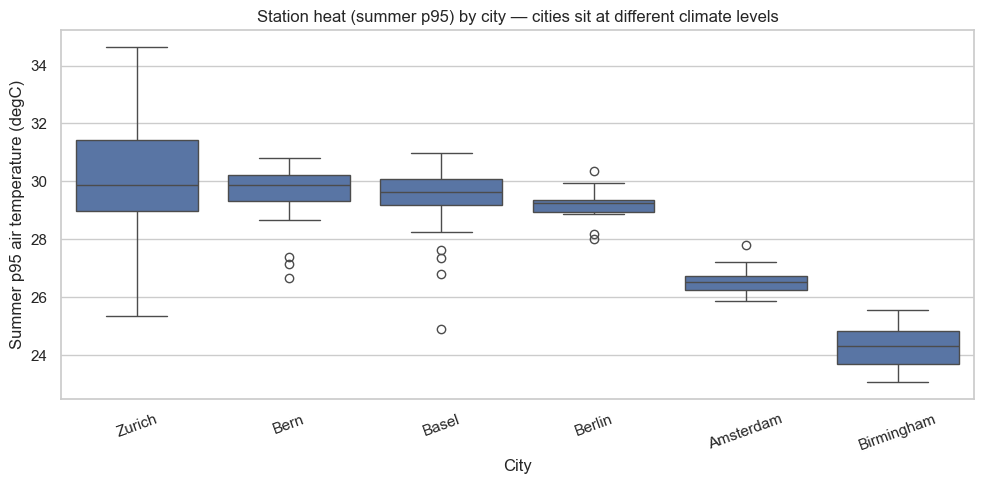

In [7]:
order = df.groupby('city')['p95'].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=df, x='city', y='p95', order=order, ax=ax)
ax.set_xlabel('City'); ax.set_ylabel('Summer p95 air temperature (degC)')
ax.set_title('Station heat (summer p95) by city — cities sit at different climate levels')
plt.xticks(rotation=20); plt.tight_layout(); plt.show()

### 4.2 Microclimate exists within every city

Within a single city, stations still differ by several degrees. That within-city
spread is the microclimate signal our local-hotspot target tries to predict. The
plot below shows, for each city, how far its hottest stations sit above its
coolest, confirming there is a real within-city range to explain.

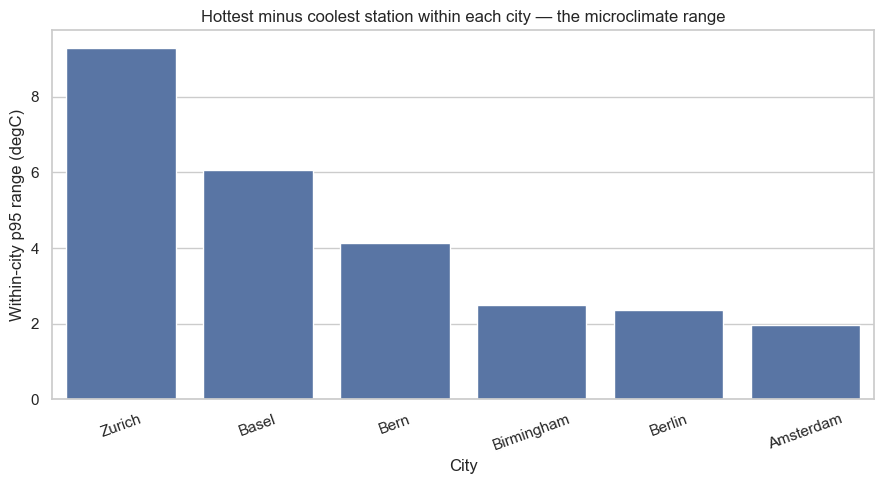

              min    max  range
city                           
Zurich      25.34  34.63   9.29
Basel       24.92  31.00   6.08
Bern        26.67  30.80   4.13
Birmingham  23.06  25.57   2.50
Berlin      28.00  30.36   2.36
Amsterdam   25.87  27.82   1.95


In [8]:
spread = (df.groupby('city')['p95'].agg(['min', 'max'])
            .assign(range=lambda d: d['max'] - d['min'])
            .sort_values('range', ascending=False))
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=spread.index, y=spread['range'], ax=ax)
ax.set_xlabel('City'); ax.set_ylabel('Within-city p95 range (degC)')
ax.set_title('Hottest minus coolest station within each city — the microclimate range')
plt.xticks(rotation=20); plt.tight_layout(); plt.show()
print(spread.round(2).to_string())

### 4.3 Do the new spatial features track heat?

A quick check that the engineered features carry signal worth modeling. We plot
neighbourhood heat (mean p95 of the five nearest stations) against a station's
own p95; a positive trend means heat is spatially clustered, which is what the
feature is meant to capture.

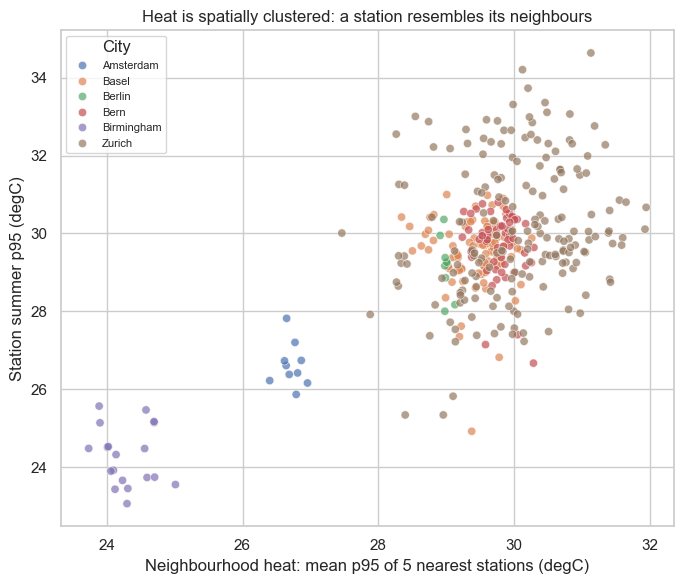

Correlation(neighbour p95, own p95) = 0.68


In [9]:
fig, ax = plt.subplots(figsize=(7, 6))
sns.scatterplot(data=df, x='knn_p95_k5', y='p95', hue='city', ax=ax, alpha=0.7)
ax.set_xlabel('Neighbourhood heat: mean p95 of 5 nearest stations (degC)')
ax.set_ylabel('Station summer p95 (degC)')
ax.set_title('Heat is spatially clustered: a station resembles its neighbours')
ax.legend(title='City', fontsize=8, loc='best')
plt.tight_layout(); plt.show()
corr = df['knn_p95_k5'].corr(df['p95'])
print(f'Correlation(neighbour p95, own p95) = {corr:.2f}')

## 5. Modeling approach

The screening question is naturally a **classification** problem: given a
station's location and context, is it a hotspot? Classification also gives us
the evaluation tools a screening decision needs, above all the ability to tune
how aggressively we flag stations. We build a ladder of models, from a trivial
baseline to an interpretable linear model to a flexible non-linear one, and we
run the whole ladder on **both** targets so the absolute-versus-within-city
contrast is built into the design rather than added as an afterthought.

We expect only modest skill from geography alone, and that expectation is itself
a finding: the true drivers of microclimate (land cover, building density,
surface sealing) are not in this dataset. A simple model that we can explain is
worth more here than a complex one we cannot.

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
dummy = make_pipeline(DummyClassifier(strategy='stratified', random_state=RANDOM_STATE), add_knn=True)
logit = GridSearchCV(
    make_pipeline(LogisticRegression(class_weight='balanced', max_iter=1000,
                                     random_state=RANDOM_STATE), add_knn=True),
    param_grid={'clf__C': [0.1, 1.0, 10.0]},
    scoring='average_precision', cv=cv, n_jobs=-1,
)
rf = GridSearchCV(
    make_pipeline(RandomForestClassifier(class_weight='balanced',
                                         random_state=RANDOM_STATE, n_jobs=-1), add_knn=True),
    param_grid={'clf__n_estimators': [200, 400], 'clf__max_depth': [3, 5, None]},
    scoring='average_precision', cv=cv, n_jobs=-1,
)
logit.fit(X, y_abs); rf.fit(X, y_abs)
print('LogReg best params:', logit.best_params_)
print('RF best params:    ', rf.best_params_)

LogReg best params: {'clf__C': 10.0}
RF best params:     {'clf__max_depth': 5, 'clf__n_estimators': 200}


## 6. Validation and results

We judge every model by cross-validation: the data are split into five folds,
each fold is predicted by a model trained on the other four, and we score the
out-of-fold predictions. This simulates predicting stations the model has not
seen. We report ROC-AUC (ranking quality across all thresholds) and PR-AUC
(precision against the minority hotspot class, the metric that matters when
positives are rare). A no-skill model scores about 0.5 on ROC-AUC.

### 6.1 The contrast, and whether new features change it

The table below crosses the two targets with the two feature sets. The earlier
finding was that the **absolute** target is predictable from geography while the
**within-city** target is not. Here we ask whether the new spatial features
(neighbourhood heat, density, direction, elevation) move the within-city number
off chance. Whatever the answer, it is informative: a lift means microclimate is
partly recoverable from spatial structure; no lift confirms that the missing
ingredient is data we do not have.

In [11]:
def oof(estimator, yt):
    cv_t = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    return cross_val_predict(estimator, X, yt, cv=cv_t, method='predict_proba')[:, 1]

def pipe_geo(clf):
    pre = ColumnTransformer([
        ('num', Pipeline([('impute', SimpleImputer(strategy='median')),
                          ('scale', StandardScaler())]), NUM_FEATURES_BASE),
        ('cat', OneHotEncoder(handle_unknown='ignore'), CAT_FEATURES),
    ])
    return Pipeline([('pre', pre), ('clf', clf)])

def fresh_models(add_knn):
    mk = (lambda clf: make_pipeline(clf, add_knn=True)) if add_knn else pipe_geo
    return {
        'Dummy (stratified)': mk(DummyClassifier(strategy='stratified', random_state=RANDOM_STATE)),
        'LogReg (balanced)':  mk(LogisticRegression(class_weight='balanced', max_iter=1000,
                                                    C=logit.best_params_['clf__C'], random_state=RANDOM_STATE)),
        'RandomForest':       mk(RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE,
                                                        n_jobs=-1, **{k.replace('clf__',''):v for k,v in rf.best_params_.items()})),
    }

targets = {'absolute': y_abs, 'within-city': y_loc}
proba, rows = {}, []
for fs_name, add_knn in [('geography-only', False), ('enriched', True)]:
    for tname, yt in targets.items():
        for mname, est in fresh_models(add_knn).items():
            p = oof(est, yt)
            proba[(tname, mname, fs_name)] = p
            rows.append({'target': tname, 'features': fs_name, 'model': mname,
                         'ROC-AUC': roc_auc_score(yt, p),
                         'PR-AUC': average_precision_score(yt, p)})
contrast = pd.DataFrame(rows).set_index(['target', 'features', 'model']).round(3)
print(contrast)

p_best = proba[('absolute', 'RandomForest', 'enriched')]
best_name = 'RandomForest (absolute, enriched)'
abs_rf = contrast.loc[('absolute', 'enriched', 'RandomForest'), 'ROC-AUC']
loc_rf = contrast.loc[('within-city', 'enriched', 'RandomForest'), 'ROC-AUC']
print(f'\nAbsolute RF ROC-AUC (enriched): {abs_rf:.3f}')
print(f'Within-city RF ROC-AUC (enriched): {loc_rf:.3f}')
assert abs_rf > 0.60, 'absolute model lost its skill — investigate'

                                               ROC-AUC  PR-AUC
target      features       model                              
absolute    geography-only Dummy (stratified)    0.521   0.262
                           LogReg (balanced)     0.650   0.344
                           RandomForest          0.682   0.390
within-city geography-only Dummy (stratified)    0.491   0.253
                           LogReg (balanced)     0.396   0.210
                           RandomForest          0.503   0.271
absolute    enriched       Dummy (stratified)    0.521   0.262
                           LogReg (balanced)     0.684   0.375
                           RandomForest          0.698   0.401
within-city enriched       Dummy (stratified)    0.491   0.253
                           LogReg (balanced)     0.511   0.278
                           RandomForest          0.526   0.281

Absolute RF ROC-AUC (enriched): 0.698
Within-city RF ROC-AUC (enriched): 0.526


**What the table shows.** Read it as two stories. The absolute target is
predictable. The RandomForest reaches a ROC-AUC of 0.698 with the enriched
features, well above the 0.52 of the stratified dummy. The within-city target
is not. The same model reaches only 0.526, close to the no-skill line of 0.5.
The new spatial features help a little on both targets. The absolute score rises
from 0.682 to 0.698, and the within-city score rises from 0.503 to 0.526. The
lift is real but small, and it is not enough to make the within-city model
useful. The contrast that frames this project survives. From the geography we
have, between-city heat is predictable and within-city microclimate is not. The
features that would close that gap, such as land cover and building density, are
not in this dataset.

### 6.2 ROC and precision-recall curves (working model)

We focus the operating-point analysis on the model that actually has skill: the
absolute-target RandomForest with the enriched features. The ROC curve shows the
trade-off between catching true hotspots and raising false alarms across all
thresholds; the precision-recall curve is the more honest view here because
hotspots are the minority class.

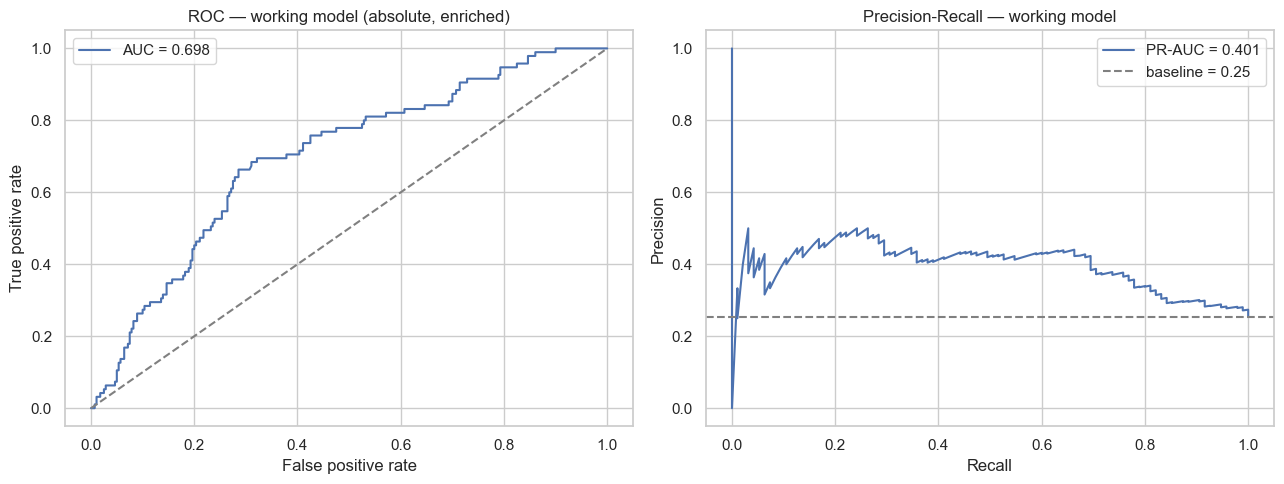

In [12]:
fpr, tpr, _ = roc_curve(y_abs, p_best)
prec, rec, _ = precision_recall_curve(y_abs, p_best)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(fpr, tpr, label=f'AUC = {roc_auc_score(y_abs, p_best):.3f}')
axes[0].plot([0, 1], [0, 1], '--', color='grey')
axes[0].set_xlabel('False positive rate'); axes[0].set_ylabel('True positive rate')
axes[0].set_title('ROC — working model (absolute, enriched)'); axes[0].legend()
axes[1].plot(rec, prec, label=f'PR-AUC = {average_precision_score(y_abs, p_best):.3f}')
axes[1].axhline(y_abs.mean(), ls='--', color='grey', label=f'baseline = {y_abs.mean():.2f}')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall — working model'); axes[1].legend()
plt.tight_layout(); plt.show()

### 6.3 Choosing the screening threshold

The default 0.5 cut-off is rarely the right screening decision. Missing a real
hotspot (a false negative) means a genuinely hot area goes unprotected, which we
treat as more costly than a false alarm (wasting a site visit). We weight a miss
three times a false alarm and pick the threshold that minimises the total cost.
This makes the screening posture explicit rather than an accident of the default.

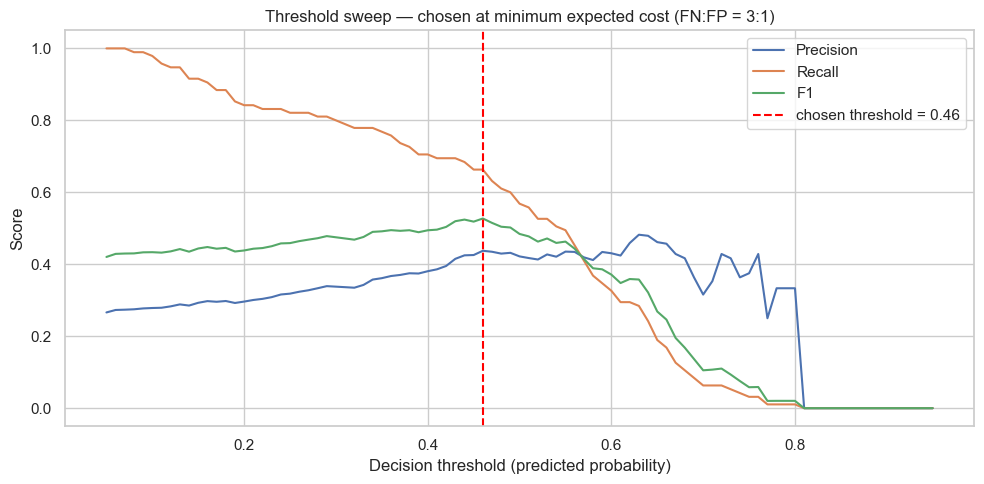

Chosen threshold: 0.46
 thr  precision  recall    f1  cost
0.46      0.438   0.663 0.527   177


In [13]:
COST_FN, COST_FP = 3, 1
def metrics_at(yt, p, thr):
    yh = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(yt, yh).ravel()
    return {'thr': thr, 'precision': precision_score(yt, yh, zero_division=0),
            'recall': recall_score(yt, yh, zero_division=0),
            'f1': f1_score(yt, yh, zero_division=0),
            'cost': COST_FN * fn + COST_FP * fp}
grid = np.linspace(0.05, 0.95, 91)
sweep = pd.DataFrame([metrics_at(y_abs, p_best, t) for t in grid])
t_star = float(sweep.loc[sweep['cost'].idxmin(), 'thr'])

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(sweep['thr'], sweep['precision'], label='Precision')
ax.plot(sweep['thr'], sweep['recall'], label='Recall')
ax.plot(sweep['thr'], sweep['f1'], label='F1')
ax.axvline(t_star, ls='--', color='red', label=f'chosen threshold = {t_star:.2f}')
ax.set_xlabel('Decision threshold (predicted probability)')
ax.set_ylabel('Score'); ax.set_title('Threshold sweep — chosen at minimum expected cost (FN:FP = 3:1)')
ax.legend(); plt.tight_layout(); plt.show()
print(f'Chosen threshold: {t_star:.2f}')
print(pd.DataFrame([metrics_at(y_abs, p_best, t_star)]).round(3).to_string(index=False))

At the chosen threshold we inspect the stations the model gets wrong. If the
false negatives and false positives share traits — sitting at the city edge, an
unusual sensor height, one particular city — that tells us where the screen is
weakest and what a human reviewer should double-check.

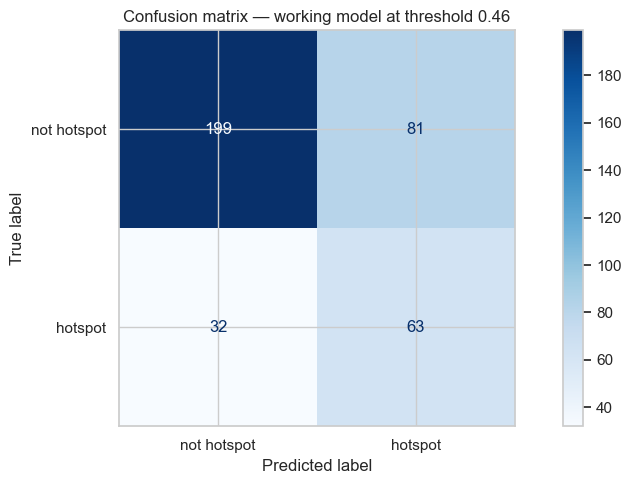

113 misclassified stations at threshold 0.46:
  city  p95 (degC)  distance to centroid (km)  sensor height (m)  P(hotspot)  y_true
 Basel       30.42                       2.38                3.0        0.13       1
 Basel       30.41                       0.65                3.0        0.11       1
 Basel       31.00                       0.81                3.0        0.19       1
 Basel       30.70                       4.03                3.0        0.12       1
 Basel       30.43                       2.20                3.0        0.14       1
 Basel       30.48                       1.58                3.0        0.10       1
 Basel       30.70                       4.98                3.0        0.19       1
 Basel       29.15                       0.57                3.0        0.55       0
 Basel       30.90                       3.07                3.0        0.18       1
 Basel       30.98                       1.83                3.0        0.13       1
 Basel       30.50 

In [14]:
yhat_star = (p_best >= t_star).astype(int)
ConfusionMatrixDisplay(confusion_matrix(y_abs, yhat_star),
                       display_labels=['not hotspot', 'hotspot']).plot(cmap='Blues')
plt.title(f'Confusion matrix — working model at threshold {t_star:.2f}')
plt.tight_layout(); plt.show()

err = df.copy()
err['y_true'] = y_abs.to_numpy(); err['y_pred'] = yhat_star; err['p_hotspot'] = p_best
wrong = err[err['y_true'] != err['y_pred']]
show = (wrong[['city', 'p95', 'distance_to_centroid', 'sensor_height_parsed', 'p_hotspot', 'y_true']]
        .rename(columns={'p95': 'p95 (degC)', 'distance_to_centroid': 'distance to centroid (km)',
                         'sensor_height_parsed': 'sensor height (m)', 'p_hotspot': 'P(hotspot)'}))
print(f'{len(wrong)} misclassified stations at threshold {t_star:.2f}:')
print(show.round(2).to_string(index=False))
print('\nMisclassifications by city:'); print(wrong['city'].value_counts().to_string())

### 6.4 Can the model transfer to a city it has never seen?

Cross-validation above mixes all six cities into every fold, so the model always
trains on some stations from each city. A screening tool is more useful if it
works in a city with no training data at all. We test this with leave-one-city-out
validation: train on five cities, predict the sixth, and repeat. We score the
absolute target, the one with real skill. A large drop from the mixed-fold score
would mean the model leans on city-specific quirks rather than a transferable
pattern. Two cities (Amsterdam, Berlin) have only ten stations each, so their
held-out scores are noisy; we report every city and read the pattern, not any
single number.

In [15]:
gkf = GroupKFold(n_splits=df['city'].nunique())
rows = []
for tr, te in gkf.split(X, y_abs, groups):
    held = df.iloc[te]['city'].iloc[0]
    est = make_pipeline(RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE,
                                               n_jobs=-1,
                                               **{k.replace('clf__',''):v for k,v in rf.best_params_.items()}),
                        add_knn=True)
    est.fit(X.iloc[tr], y_abs.iloc[tr])
    p = est.predict_proba(X.iloc[te])[:, 1]
    yt = y_abs.iloc[te]
    auc = roc_auc_score(yt, p) if yt.nunique() > 1 else np.nan
    rows.append({'held_out_city': held, 'n_stations': len(te),
                 'n_positive': int(yt.sum()), 'ROC-AUC': auc})
transfer = pd.DataFrame(rows).sort_values('n_stations', ascending=False)
transfer_mean = transfer['ROC-AUC'].mean()
print(transfer.round(3).to_string(index=False))
print(f'\nMean leave-one-city-out ROC-AUC: {transfer_mean:.3f}')
print(f'(Compare to mixed-fold absolute RF ROC-AUC computed in Section 6.1.)')

held_out_city  n_stations  n_positive  ROC-AUC
       Zurich         184          72    0.564
        Basel          97          11    0.420
         Bern          55          11    0.463
   Birmingham          19           0      NaN
       Berlin          10           1    0.111
    Amsterdam          10           0      NaN

Mean leave-one-city-out ROC-AUC: 0.390
(Compare to mixed-fold absolute RF ROC-AUC computed in Section 6.1.)


**What the transfer test shows.** The mixed-fold score of about 0.70 does not
survive when a whole city is held out. The mean leave-one-city-out ROC-AUC falls
to about 0.39, at or below chance. The three cities with enough hotspots to
score tell the same story. Zurich reaches 0.564, Basel 0.420, and Bern 0.463.
Birmingham and Amsterdam have no absolute hotspots at all, so they cannot be
scored. The reason is instructive. Much of the absolute model's skill comes from
learning each city's own climate level. When a city is entirely new, that anchor
is gone, and the model cannot place it on the temperature scale. So the screen
works among cities it has already seen. It does not yet transfer to a city with
no training data. A tool meant for new cities would need features that carry
climate information directly, rather than a city label learned from examples.

### 6.5 Would more data or better features help more?

A learning curve trains the model on increasing fractions of the data and plots
the cross-validated score. If the validation score is still climbing at the full
sample, more stations would help. If the two curves have met and flattened at a
modest level, the model has learned what it can from these features and the limit
is the features themselves — more rows would not help, but better inputs (land
cover, density) would. This diagnosis is the evidence behind our recommendation
in Section 8.

/Users/sunnytamrakar/Documents/KS/CDAP/computational-data-analysis/.venv/lib/python3.12/site-packages/sklearn/impute/_base.py:641: UserWarning: Skipping features without any observed values: ['altitude_m']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/sunnytamrakar/Documents/KS/CDAP/computational-data-analysis/.venv/lib/python3.12/site-packages/sklearn/impute/_base.py:641: UserWarning: Skipping features without any observed values: ['altitude_m']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/sunnytamrakar/Documents/KS/CDAP/computational-data-analysis/.venv/lib/python3.12/site-packages/sklearn/impute/_base.py:641: UserWarning: Skipping features without any observed values: ['altitude_m']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/sunnytamrakar/Documents/KS/CDAP/computational-data-analysis/.venv/lib/python3.12/

/Users/sunnytamrakar/Documents/KS/CDAP/computational-data-analysis/.venv/lib/python3.12/site-packages/sklearn/impute/_base.py:641: UserWarning: Skipping features without any observed values: ['altitude_m']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/sunnytamrakar/Documents/KS/CDAP/computational-data-analysis/.venv/lib/python3.12/site-packages/sklearn/impute/_base.py:641: UserWarning: Skipping features without any observed values: ['altitude_m']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/sunnytamrakar/Documents/KS/CDAP/computational-data-analysis/.venv/lib/python3.12/site-packages/sklearn/impute/_base.py:641: UserWarning: Skipping features without any observed values: ['altitude_m']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


/Users/sunnytamrakar/Documents/KS/CDAP/computational-data-analysis/.venv/lib/python3.12/site-packages/sklearn/impute/_base.py:641: UserWarning: Skipping features without any observed values: ['altitude_m']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/sunnytamrakar/Documents/KS/CDAP/computational-data-analysis/.venv/lib/python3.12/site-packages/sklearn/impute/_base.py:641: UserWarning: Skipping features without any observed values: ['altitude_m']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/sunnytamrakar/Documents/KS/CDAP/computational-data-analysis/.venv/lib/python3.12/site-packages/sklearn/impute/_base.py:641: UserWarning: Skipping features without any observed values: ['altitude_m']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


/Users/sunnytamrakar/Documents/KS/CDAP/computational-data-analysis/.venv/lib/python3.12/site-packages/sklearn/impute/_base.py:641: UserWarning: Skipping features without any observed values: ['altitude_m']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/sunnytamrakar/Documents/KS/CDAP/computational-data-analysis/.venv/lib/python3.12/site-packages/sklearn/impute/_base.py:641: UserWarning: Skipping features without any observed values: ['altitude_m']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/sunnytamrakar/Documents/KS/CDAP/computational-data-analysis/.venv/lib/python3.12/site-packages/sklearn/impute/_base.py:641: UserWarning: Skipping features without any observed values: ['altitude_m']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


/Users/sunnytamrakar/Documents/KS/CDAP/computational-data-analysis/.venv/lib/python3.12/site-packages/sklearn/impute/_base.py:641: UserWarning: Skipping features without any observed values: ['altitude_m']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/Users/sunnytamrakar/Documents/KS/CDAP/computational-data-analysis/.venv/lib/python3.12/site-packages/sklearn/impute/_base.py:641: UserWarning: Skipping features without any observed values: ['altitude_m']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


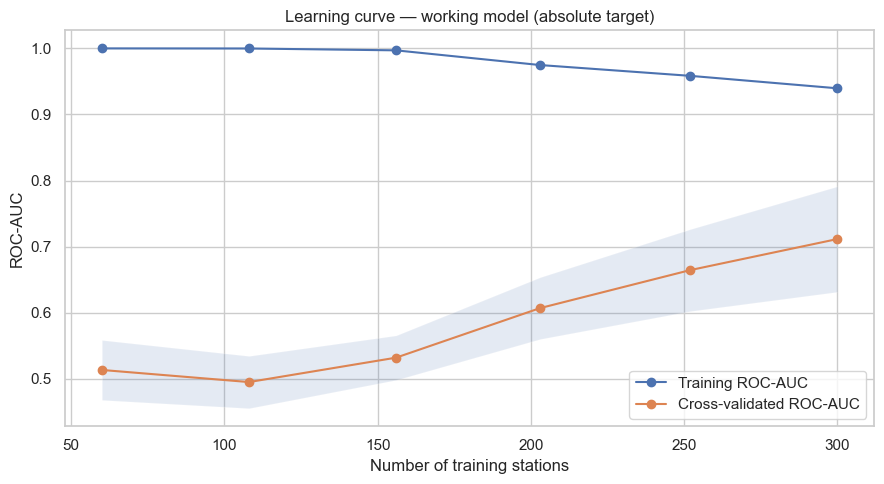

Training stations: [60, 108, 156, 203, 252, 300]
CV ROC-AUC by size: [np.float64(0.513), np.float64(0.495), np.float64(0.532), np.float64(0.607), np.float64(0.664), np.float64(0.711)]
Train vs CV ROC-AUC at full size: 0.940 vs 0.711


In [16]:
lc_est = make_pipeline(RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE,
                                              n_jobs=-1,
                                              **{k.replace('clf__',''):v for k,v in rf.best_params_.items()}),
                       add_knn=True)
sizes, train_scores, val_scores = learning_curve(
    lc_est, X, y_abs, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
    scoring='roc_auc', train_sizes=np.linspace(0.2, 1.0, 6), n_jobs=-1,
)
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(sizes, train_scores.mean(1), 'o-', label='Training ROC-AUC')
ax.plot(sizes, val_scores.mean(1), 'o-', label='Cross-validated ROC-AUC')
ax.fill_between(sizes, val_scores.mean(1)-val_scores.std(1), val_scores.mean(1)+val_scores.std(1), alpha=0.15)
ax.set_xlabel('Number of training stations'); ax.set_ylabel('ROC-AUC')
ax.set_title('Learning curve — working model (absolute target)')
ax.legend(); plt.tight_layout(); plt.show()
print('Training stations:', [int(s) for s in sizes])
print('CV ROC-AUC by size:', [round(v, 3) for v in val_scores.mean(1)])
print(f'Train vs CV ROC-AUC at full size: {train_scores.mean(1)[-1]:.3f} vs {val_scores.mean(1)[-1]:.3f}')

**What the learning curve shows.** The cross-validated score rises steadily as
we add stations. It climbs from about 0.51 at 60 stations to 0.71 at the full
300, and it has not flattened. So more stations would still raise performance
for the absolute model. At the same time the training score stays near 0.94,
well above the validation score. That gap is variance. The model fits its
training stations more closely than it generalises. Both signs point the same
way for the absolute task, and more data would help it. The within-city task is
different. There the scores sit at chance whatever the feature set, as Section
6.1 showed, so its limit is the features rather than the sample. The practical
reading is simple. More stations would sharpen the between-city screen, while
only richer features would unlock the within-city one.

## 7. Uncertainty and limitations

A single ROC-AUC number hides how much it could shift if we had sampled
different stations. With only a few hundred stations this matters. We quantify it
by bootstrapping: we resample the stations with replacement many times, recompute
the score each time, and report the 2.5th-97.5th percentile range as a 95%
confidence interval. This lets us say whether the gap between the absolute model
and the within-city model is real or could be noise.

     target  ROC-AUC  boot_mean  CI_low  CI_high
   absolute    0.698      0.699   0.637    0.755
within-city    0.526      0.525   0.458    0.589


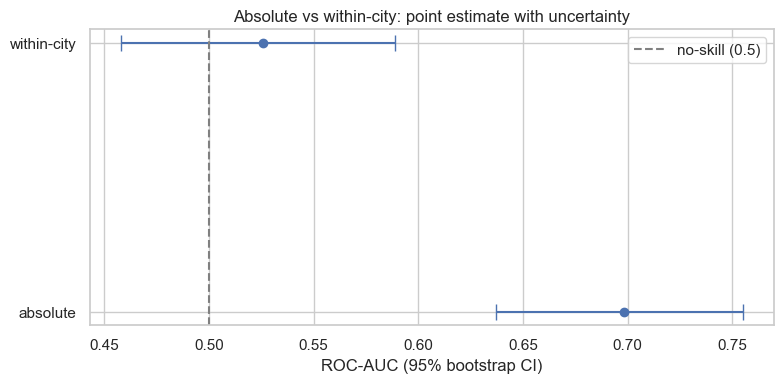

In [17]:
def bootstrap_auc(yt, p, n_boot=2000):
    yt = np.asarray(yt); p = np.asarray(p); n = len(yt)
    stats = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        if np.unique(yt[idx]).size < 2:
            continue
        stats.append(roc_auc_score(yt[idx], p[idx]))
    lo, hi = np.percentile(stats, [2.5, 97.5])
    return np.mean(stats), lo, hi

rows = []
for tname, yt in [('absolute', y_abs), ('within-city', y_loc)]:
    p = proba[(tname, 'RandomForest', 'enriched')]
    mean, lo, hi = bootstrap_auc(yt, p)
    rows.append({'target': tname, 'ROC-AUC': roc_auc_score(yt, p),
                 'boot_mean': mean, 'CI_low': lo, 'CI_high': hi})
ci = pd.DataFrame(rows).round(3)
print(ci.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(ci['ROC-AUC'], ci['target'],
            xerr=[ci['ROC-AUC']-ci['CI_low'], ci['CI_high']-ci['ROC-AUC']],
            fmt='o', capsize=6)
ax.axvline(0.5, ls='--', color='grey', label='no-skill (0.5)')
ax.set_xlabel('ROC-AUC (95% bootstrap CI)'); ax.set_ylabel('')
ax.set_title('Absolute vs within-city: point estimate with uncertainty')
ax.legend(); plt.tight_layout(); plt.show()

### 7.1 What this analysis can and cannot say

The confidence intervals frame two kinds of uncertainty. **Epistemic** uncertainty
is the part we could shrink with more or better data: the wide intervals come
partly from a small sample, and the modest scores come from features that only
proxy the real drivers. **Aleatoric** uncertainty is irreducible: a station's
heat depends on fine-scale surroundings that no amount of coordinates will fully
capture.

Honest limitations of the study:

- The features are thin. Latitude, longitude, distance, direction, density and
  sensor height are weak stand-ins for what actually drives microclimate, namely
  land cover, surface sealing and building density. We name this as the main
  reason the within-city signal is hard to predict.
- The within-city label is **relative**. A within-city hotspot in a cool city is
  not hot in absolute terms, so the two views must be read together.
- The sample is small (a few hundred stations, two cities with only ten), which
  widens every interval and makes the cross-city scores for small cities noisy.
- Climate is excluded from the within-city target by design, to isolate
  microclimate; that is a deliberate scope choice, not an oversight.

## 8. Decision-oriented interpretation and recommendation

We can now turn the results into advice a city could use. The recommendation has
two tiers, one for each lens.

First, use the absolute view to decide which cities and areas deserve attention.
This view is predictable, and its skill is backed by a confidence interval that
stays above chance. A planner working across several instrumented cities can use
it to rank locations by heat and focus on the warmest.

Second, inside a chosen city, use the working model to shortlist candidate hot
spots for a site visit. At the chosen threshold of 0.46 the screen catches about
66% of the true hotspots, and about 44% of the stations it flags turn out to be
real hotspots. We set the threshold this way on purpose. Missing a genuinely hot
area is worse than sending a reviewer to a location that turns out to be
ordinary, so we accept more false alarms in order to catch more real cases. The
model is a filter that produces a shortlist, not a final verdict. A human should
confirm each flagged site.

Two cautions come with the advice. The within-city model is not reliable enough
to deploy on its own. Its score sits at chance and its confidence interval
includes 0.5, so it cannot yet separate local hot spots inside a city. And the
absolute model should be used only in cities where we already have stations,
because it does not transfer to a city it has never seen.

The most valuable next step is clear from the evidence. The within-city gap is a
feature problem, not a sample problem, so real land cover, surface sealing, and
building density would most likely lift the microclimate model. The learning
curve also shows that more stations would help the absolute screen. The priority
is richer features first and more stations second.

## 9. Conclusion

We set out to screen urban locations for summer heat risk. We measured each
station's heat with its summer p95 and studied risk through two lenses, absolute
and within-city. The central finding is a contrast. Between-city heat is
predictable from geography, with a ROC-AUC near 0.70, while within-city
microclimate is not and sits at chance. New spatial features built from the
coordinates we already hold lifted the scores only slightly and did not change
this picture. Two checks tell us how far to trust the result. Bootstrap
confidence intervals separate the two lenses cleanly, and a leave-one-city-out
test shows the absolute model does not transfer to an unseen city. The honest
conclusion is that we can screen heat between and within the cities we already
monitor, but the data we have cannot yet explain microclimate or generalise to
new cities. The clearest path forward is better features, above all real land
cover.